# Lab 03 · Notebook principal actualizado
**Kalman 2: media y log-varianza**. Tres pares exploratorios, sin Risk Parity conforme a la indicación verbal del profesor.

Este notebook lee resultados reales de la ejecución local, no simula precios ni modifica parámetros con test/validación. **Primero** ejecuta desde terminal: `python main.py`, `python generar_bitacoras.py`, `python calibrar_walkforward.py` (en ese orden). El comparador de rebalanceo también debe regenerarse si se mostrará como evidencia actual.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT/'main.py').exists() and (ROOT.parent/'main.py').exists(): ROOT=ROOT.parent
if not (ROOT/'main.py').exists(): raise FileNotFoundError('Abre el notebook desde la raíz del Lab 03')
sys.path.insert(0,str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from config import CFG, PAIRS
ART=ROOT/'artifacts'
print('Ruta:',ROOT,'| pares:',PAIRS,'| semilla:',42)

Ruta: /Users/erikdelcastilloroman/ITESO - INFI/Sistemas de trading/Lab03_MyST_Equipo5 | pares: {'NWS_NWSA': ('NWS', 'NWSA'), 'GOOG_GOOGL': ('GOOG', 'GOOGL'), 'TLT_VGLT': ('TLT', 'VGLT')} | semilla: 42


## 1. Diseño del experimento y advertencias
- Datos ajustados desde 2014, división cronológica 60/20/20.
- **NWS–NWSA:** seleccionable inicialmente, con inestabilidad fuera de muestra.
- **GOOG–GOOGL:** Johansen principal rango 2; no confirma rango 1.
- **TLT–VGLT:** no superó corrección FDR.
- Cada par cuenta con USD 1 millón en una simulación independiente. No es un portafolio combinado.
- La política original permanece en `main.py`; los parámetros calibrados están en los CSV walk-forward y **no** se aplican automáticamente al pipeline principal.

In [2]:
from data.loader import get_prices, split_602020
prices=get_prices(list(dict.fromkeys(t for p in PAIRS.values() for t in p)))
print('Observaciones:',len(prices),'Desde:',prices.index.min(),'Hasta:',prices.index.max())
for name,(a,b) in PAIRS.items():
    x=prices[[a,b]].dropna(); t,te,v=split_602020(x)
    print(name,len(t),len(te),len(v))

Observaciones: 3230 Desde: 2014-01-02 00:00:00 Hasta: 2026-11-04 00:00:00
NWS_NWSA 1938 646 646
GOOG_GOOGL 1938 646 646
TLT_VGLT 1938 646 646


## 2. Selección: Engle-Granger, Johansen y ADF
El screening se calcula únicamente en entrenamiento, no constituye prueba de estabilidad futura.

In [3]:
from cointegration.screen import screening
rows=[]
for name,tickers in PAIRS.items():
    result=screening(prices[list(tickers)].dropna())
    rows.append({'par':name,**result})
display(pd.DataFrame(rows)[['par','correlation','engle_granger_p','johansen_trace_rank','johansen_eigen_rank','screen_pass']])

/Users/erikdelcastilloroman/ITESO - INFI/Sistemas de trading/Lab03_MyST_Equipo5/cointegration/screen.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p=float(adfuller(spread,regression='c',autolag='aic')[1])
/Users/erikdelcastilloroman/ITESO - INFI/Sistemas de trading/Lab03_MyST_Equipo5/cointegration/screen.py:21: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  i1 =

,par,correlation,engle_granger_p,johansen_trace_rank,johansen_eigen_rank,screen_pass
0,NWS_NWSA,0.996531,0.000664,1,1,True
1,GOOG_GOOGL,0.999740,0.000029,2,2,False
2,TLT_VGLT,0.999837,0.025282,1,1,True


## 3. Modelos y causalidad
Kalman 1: estado [intercepto, hedge ratio], Q=1e-5 I, R=4.
Kalman 2: estado de media y **log-varianza** con dos actualizaciones recursivas acopladas. Predice media y volatilidad antes de usar la innovación corriente; la varianza usa una pseudo-observación log-cuadrática corregida por sesgo. No es un Kalman gaussiano conjunto exacto.
VECM: estimado solo en entrenamiento; innovaciones proyectadas en beta de Kalman anterior. Señal en cierre t y ejecución cierre t+1. Este z-score de innovaciones **no equivale** al z-score de desviación del spread de cointegración.

In [4]:
from kalman.filters import signal_filter
import inspect
print('Interfaz:',inspect.signature(signal_filter))
# Ejemplo ilustrativo, NO dato de mercado
illustrative=np.array([0.0,0.2,-0.4,0.8,-0.5,0.1]*8)
f=signal_filter(illustrative)
display(pd.DataFrame({k:v for k,v in f.items() if k in ['z','predictive_mean','predictive_sigma','predictive_log_variance','variance_gain']}).tail(5))

Interfaz: (values, q=0.0001, r=0.01, burn_in=30, q_logvar=0.01, r_logvar=4.934802200544679, min_variance=1e-08)


,z,predictive_mean,predictive_sigma,predictive_log_variance,variance_gain
43,0.469700,0.026865,0.368608,-2.003812,0.045121
44,-1.209035,0.043340,0.366689,-2.014334,0.045025
45,2.099315,0.001156,0.380526,-1.939689,0.044937
46,-1.426123,0.077162,0.404707,-1.815624,0.044857
47,0.183792,0.022250,0.423032,-1.726506,0.044784


## 4. Métricas originales fuera de muestra
Estos artefactos deben haberse regenerado **después** de instalar el filtro actualizado. Si el CSV es anterior, los números no corresponderán a esta versión.

In [5]:
metrics=pd.read_csv(ART/'metrics.csv')
display(metrics[['pair','screen_pass','total_return','sharpe','max_drawdown','commissions','borrow_cost']])

,pair,screen_pass,total_return,sharpe,max_drawdown,commissions,borrow_cost
0,NWS_NWSA,True,-0.136499,-2.390383,-0.136869,116367.814305,390.046829
1,GOOG_GOOGL,False,-0.128624,-4.058319,-0.129529,131940.173180,530.520479
2,TLT_VGLT,True,-0.069499,-3.558760,-0.069499,72113.703389,312.753822


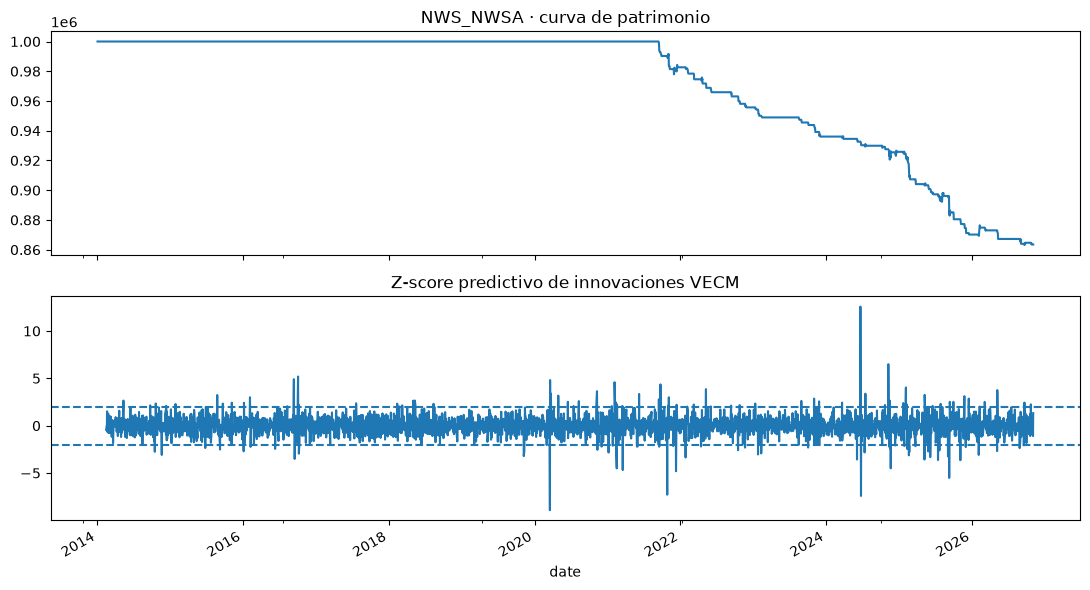

In [14]:
pair = "NWS_NWSA"
bt=pd.read_csv(ART/f'{pair}_backtest.csv',parse_dates=['date']).set_index('date')
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True)
bt.equity.plot(ax=axes[0],title=f'{pair} · curva de patrimonio')
bt.kalman2_z.plot(ax=axes[1],title='Z-score predictivo de innovaciones VECM')
axes[1].axhline(2,ls='--'); axes[1].axhline(-2,ls='--');plt.tight_layout();plt.show()

## 5. Resultados walk-forward: sin selección en validación
El grid se decide con ventanas de entrenamiento; test y validación se utilizan para reportar desempeño, no para volver a elegir parámetros.

In [7]:
wf=pd.read_csv(ART/'walkforward_oos_comparison.csv')
display(wf[['pair','policy','partition','entry_z','exit_z','return_net','sharpe','commission','trade_days']])
summary=[]
for pair,g in wf.groupby('pair'):
  for policy,h in g.groupby('policy'):
    summary.append({'par':pair,'politica':policy,'OOS_compuesto':np.prod(1+h.return_net.to_numpy())-1,'comisiones_oos':h.commission.sum()})
display(pd.DataFrame(summary))

,pair,policy,partition,entry_z,exit_z,return_net,sharpe,commission,trade_days
0,NWS_NWSA,baseline,test,2.0,0.50,-0.065458,-2.927408,52583.151855,87
1,NWS_NWSA,baseline,validation,2.0,0.50,-0.076018,-2.149921,63784.662450,129
2,NWS_NWSA,seleccion_train,test,2.5,0.25,-0.025926,-1.097922,22506.302193,64
3,NWS_NWSA,seleccion_train,validation,2.5,0.25,-0.053650,-1.640875,40489.293673,104
4,GOOG_GOOGL,baseline,test,2.0,0.50,-0.056793,-3.823088,55553.291280,120
5,GOOG_GOOGL,baseline,validation,2.0,0.50,-0.076156,-4.288496,76386.881900,157
6,GOOG_GOOGL,seleccion_train,test,2.5,0.25,-0.029315,-2.847025,26294.974537,61
7,GOOG_GOOGL,seleccion_train,validation,2.5,0.25,-0.043503,-2.565813,43102.935409,129
8,TLT_VGLT,baseline,test,2.0,0.50,-0.035362,-3.328215,37831.507579,94
9,TLT_VGLT,baseline,validation,2.0,0.50,-0.035389,-3.840908,34282.195811,61


,par,politica,OOS_compuesto,comisiones_oos
0,GOOG_GOOGL,baseline,-0.128624,131940.173180
1,GOOG_GOOGL,seleccion_train,-0.071543,69397.909947
2,NWS_NWSA,baseline,-0.136499,116367.814305
3,NWS_NWSA,seleccion_train,-0.078185,62995.595866
4,TLT_VGLT,baseline,-0.069499,72113.703389
5,TLT_VGLT,seleccion_train,-0.024501,25998.375038


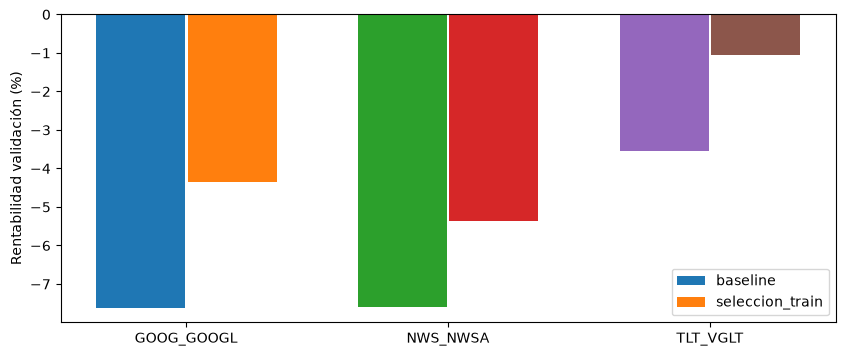

In [8]:
fig,ax=plt.subplots(figsize=(10,4))
v=wf[wf.partition=='validation']
for i,(name,g) in enumerate(v.groupby('pair')):
 for j,policy in enumerate(['baseline','seleccion_train']):
  r=g[g.policy==policy]
  if not r.empty:ax.bar(i+(j-.5)*.35,r.return_net.iloc[0]*100,width=.34,label=policy if i==0 else '')
ax.set_xticks(range(v.pair.nunique()),sorted(v.pair.unique()));ax.set_ylabel('Rentabilidad validación (%)');ax.legend();plt.show()

## 6. Bitácora y Johansen móvil
Registros operativos y diagnóstico por ventanas móviles. Usar únicamente archivos regenerados con la versión vigente; no recalibrar umbrales según resultados fuera de muestra.

In [15]:
print("Par seleccionado:", pair)
print("Carpeta de resultados:", ART.resolve())
ops=ART/f'{pair}_operaciones.csv';jfile=ART/f'{pair}_johansen_movil.csv'
if ops.exists():
 o=pd.read_csv(ops);print('Operaciones:',len(o),'cerradas:',(o.status=='cerrada').sum());display(o.head())
else:print('Ejecuta python generar_bitacoras.py')
if jfile.exists():
 jj=pd.read_csv(jfile);display(jj.tail())
else:print('Ejecuta python main.py')

Par seleccionado: NWS_NWSA
Carpeta de resultados: /Users/erikdelcastilloroman/ITESO - INFI/Sistemas de trading/Lab03_MyST_Equipo5/artifacts
Operaciones: 62 cerradas: 62


,trade_id,entry_date,exit_date,status,direction,entry_partition,exit_partition,holding_days,entry_gross_notional,gross_pnl,commissions,borrow_cost,net_pnl,net_return_on_entry_gross,entry_equity,exit_equity,rebalance_days
0,1,2021-09-15,2021-09-17,cerrada,spread_largo,test,test,2,799183.863113,-4005.037266,2010.835720,5.389216,-6021.262201,-0.007534,1000000.000000,NaN,1
1,2,2021-09-20,2021-09-21,cerrada,spread_largo,test,test,1,794380.046944,990.253927,2002.762564,2.707748,-1015.216385,-0.001278,993978.737799,NaN,0
2,3,2021-09-24,2021-09-28,cerrada,spread_corto,test,test,2,793574.001770,-710.967579,1978.199451,5.540148,-2694.707178,-0.003396,992963.521414,NaN,1
3,4,2021-10-28,2021-11-01,cerrada,spread_largo,test,test,2,791409.329788,3316.308640,2019.687678,5.388245,1291.232717,0.001632,990268.814235,NaN,1
4,5,2021-11-02,2021-11-04,cerrada,spread_corto,test,test,2,792453.697149,-5233.787916,2004.240998,5.529424,-7243.558338,-0.009141,991560.046952,NaN,1


,date,beta_a,beta_b,trace_rank,eigen_rank,trace_r0,trace_r1,error
125,2026-06-11,1.0,5.037179,1,1,12.290604,4.937300,NaN
126,2026-07-14,1.0,-2.557228,1,1,14.401246,6.878694,NaN
127,2026-08-12,1.0,-0.844442,1,1,14.550918,7.121738,NaN
128,2026-09-11,1.0,-0.882245,2,1,15.696913,5.050823,NaN
129,2026-10-12,1.0,-0.876380,2,1,18.353034,4.572214,NaN


## 7. Evaluación secuencial de Powell
**Estado:** capital, posiciones, estados y covarianzas predictivos de Kalman, parámetros VECM estimados hasta entrenamiento. **Decisión:** dirección y cantidad de posiciones objetivo. **Información exógena:** precios futuros desconocidos en t. **Transición:** actualización de patrimonio, inventario, filtros y costos. **Contribución:** P&L neto.

Para Kalman 1 y Kalman 2, identificar por separado estado, decisión estimativa, información observada, transición y actualización; el reporte contiene la formulación extendida. **La evidencia empírica no demuestra rentabilidad ni cointegración robusta para tres pares.**

## 8. Comprobación final
Desde terminal: `python -m pytest tests/ -q` y `python -m streamlit run dashboard/app.py`. La presentación principal es en Streamlit; el PDF debe incluir las capturas de la **misma ejecución final**.

In [10]:
from pathlib import Path
import pandas as pd

archivo = Path("../artifacts/NWS_NWSA_operaciones.csv").resolve()

print("Archivo utilizado:", archivo)
print("¿Existe?:", archivo.exists())

if archivo.exists():
    datos = pd.read_csv(archivo)
    print("Operaciones encontradas:", len(datos))
    print("Operaciones cerradas:", (datos["status"] == "cerrada").sum())

Archivo utilizado: /Users/erikdelcastilloroman/ITESO - INFI/Sistemas de trading/Lab03_MyST_Equipo5/artifacts/NWS_NWSA_operaciones.csv
¿Existe?: True
Operaciones encontradas: 62
Operaciones cerradas: 62
